# 04 - Numerical methods: Euler's method, its error, and better methods

**MATH 331 - Differential Equations.** Preview of unit U14 in Session 8 (Euler's method
compared with the exact solution), developed fully in Session 29 (Euler, improved Euler (Heun),
fourth-order Runge-Kutta, local and global error, order of accuracy, stiffness,
`scipy.integrate.solve_ivp`).

**References**
* J. Lebl, *Notes on Diffy Qs* (`ode/FullText_Diff_Eq_For_Engineers.pdf`): **Section 1.7,
  Numerical methods: Euler's method** (Tables 1.7.1 and 1.7.2) and the exercises of Section 1.7
  (improved Euler, Runge-Kutta, numerical instability).
* F. Meseguer (ed.), *Fundamentals of Numerical Mathematics for Physicists and Engineers*
  (Wiley, 2020), **Section 8.2, The Initial Value Problem**: local truncation and global error,
  consistency, absolute stability (eqs. 8.161-8.165).

**What you will learn**
1. Where Euler's method comes from, and why its error is proportional to $h$.
2. How to **measure** the order of a method, reproducing Lebl's Table 1.7.1 exactly.
3. Why higher-order methods (Heun, RK4) pay off.
4. Two ways numerical results can mislead: blow-up of the exact solution, and numerical
   instability (a first look at stiffness).

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (analytic solutions, Euler/Heun/RK4, slope fields, phase lines).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 1. Euler's method

For the IVP $y' = f(x,y)$, $y(x_0) = y_0$, follow the tangent line for a step $h$ (Lebl, Section 1.7):

$$
\boxed{\;x_{i+1} = x_i + h, \qquad y_{i+1} = y_i + h\,f(x_i, y_i)\;}
$$

**Where the error comes from.** If $y$ is the exact solution, Taylor's theorem gives
$y(x_i + h) = y(x_i) + h\,y'(x_i) + \tfrac{h^2}{2}y''(\xi_i)$ for some $\xi_i$ between $x_i$ and
$x_i + h$. Euler keeps the first two terms, so **one step** makes an error (the *local truncation
error*) of size $\tfrac{h^2}{2}|y''|$. Reaching a fixed $x$ takes $(x - x_0)/h$ steps, so the errors
add up to roughly $(x - x_0)\,\tfrac{h}{2}\,\max|y''|$: the **global error is $O(h)$**. Euler's
method is a **first-order** method (Meseguer, Section 8.2).

**A precise statement.** Suppose $f$ is Lipschitz in $y$ with constant $L$
($|f(x,y_1)-f(x,y_2)| \le L|y_1 - y_2|$) and $|y''| \le K$ on $[x_0, X]$. Then the Euler
approximation satisfies

$$
|y(x_n) - y_n| \;\le\; \frac{K h}{2L}\left(e^{L(x_n - x_0)} - 1\right) \qquad (x_0 \le x_n \le X).
$$

*Proof sketch.* Let $e_n = y(x_n) - y_n$. Subtracting the Euler step from the Taylor expansion,
$e_{n+1} = e_n + h\,[f(x_n, y(x_n)) - f(x_n, y_n)] + \tfrac{h^2}{2}y''(\xi_n)$, hence
$|e_{n+1}| \le (1 + hL)|e_n| + \tfrac{K h^2}{2}$. Since $e_0 = 0$, induction gives
$|e_n| \le \tfrac{Kh^2}{2}\sum_{j<n}(1+hL)^j = \tfrac{Kh}{2L}\left[(1+hL)^n - 1\right]$, and
$(1 + hL)^n \le e^{nhL}$. $\square$

The bound is linear in $h$ (first order), but it can grow **exponentially** with the length of
the interval.

## 2. Reproducing Lebl's Table 1.7.1

Lebl approximates $y(2)$ for $y' = y^2/3$, $y(0) = 1$, whose exact solution is
$y = \dfrac{3}{3 - x}$ (Exercise 1.7.1), so $y(2) = 3$. Every time $h$ is halved, the error
roughly halves (last column → 1/2), as a first-order method should.

*Note on the book.* For $h = 0.25$ the table prints 2.47250. Euler gives 2.472494, which rounds
to 2.47249. The book's own error column (0.52751) is consistent with 2.472494, so the printed
value is a rounding slip. Checking every number is part of the job!

In [2]:
f = lambda x, y: y**2 / 3                       # noqa: E731
exact_y2 = 3.0
lebl_values = [1.92593, 2.20861, 2.47250, 2.68034, 2.82040, 2.90412, 2.95035, 2.97472]
print(f"{'h':>10} {'approx y(2)':>12} {'Lebl':>9} {'error':>9} {'error/prev':>11}")
previous = None
for h, book in zip([1 / 2**i for i in range(8)], lebl_values, strict=True):
    _, y = ol.euler(f, (0.0, 2.0), 1.0, h)
    err = exact_y2 - y[-1]
    ratio = f"{err / previous:11.5f}" if previous else " " * 11
    print(f"{h:10.7f} {y[-1]:12.6f} {book:9.5f} {err:9.5f} {ratio}")
    assert abs(y[-1] - book) <= 1e-5                  # agrees with the book to its 5 decimals
    previous = err

         h  approx y(2)      Lebl     error  error/prev
 1.0000000     1.925926   1.92593   1.07407            
 0.5000000     2.208612   2.20861   0.79139     0.73681
 0.2500000     2.472494   2.47250   0.52751     0.66656
 0.1250000     2.680337   2.68034   0.31966     0.60599
 0.0625000     2.820401   2.82040   0.17960     0.56184
 0.0312500     2.904121   2.90412   0.09588     0.53385
 0.0156250     2.950355   2.95035   0.04965     0.51779
 0.0078125     2.974724   2.97472   0.02528     0.50913


## 3. Better methods: improved Euler (Heun) and Runge-Kutta 4

* **Improved Euler / Heun** (Lebl, exercises of Section 1.7, eq. 1.E.2): take an Euler step to
  guess the end point, compute the slope there, and use the **average** of the two slopes:
  $$k_1 = f(x_i, y_i),\quad k_2 = f(x_i + h, y_i + h k_1),\quad y_{i+1} = y_i + h\,\tfrac{k_1 + k_2}{2}.$$
  Second order: halving $h$ divides the error by about 4.
* **Classical Runge-Kutta (RK4)**: four slopes per step, weights $1, 2, 2, 1$ (out of 6). Fourth
  order: halving $h$ divides the error by about 16 (Lebl, Section 1.7).

**Lebl, Exercise 1.7.9**: $y' = x + y$, $y(0) = 1$, exact solution $y = 2e^x - x - 1$, so
$y(1) = 2e - 2 \approx 3.4366$. (The printed answer says "$y(2)$ is approximately 3.4366",
another small slip: $3.4366$ is $y(1)$, while $y(2) = 2e^2 - 3 \approx 11.78$.)

In [3]:
g = lambda x, y: x + y                           # noqa: E731
exact = 2 * np.e - 2
for name, method in (("Euler", ol.euler), ("Heun ", ol.heun), ("RK4  ", ol.rk4)):
    values = [method(g, (0, 1), 1.0, h)[1][-1] for h in (0.25, 0.125)]
    errors = [exact - v for v in values]
    print(f"{name}: y(1) = {values[0]:.4f} (h=1/4), {values[1]:.4f} (h=1/8); "
          f"errors {errors[0]:.6f}, {errors[1]:.6f}; factor {errors[1] / errors[0]:.3f}")
# Lebl's answers: improved Euler 3.3897 and 3.4237, standard Euler 2.8828 and 3.1316
assert abs(ol.heun(g, (0, 1), 1.0, 0.25)[1][-1] - 3.3897) < 1e-4
assert abs(ol.euler(g, (0, 1), 1.0, 0.125)[1][-1] - 3.1316) < 1e-4

Euler: y(1) = 2.8828 (h=1/4), 3.1316 (h=1/8); errors 0.553751, 0.304995; factor 0.551
Heun : y(1) = 3.3897 (h=1/4), 3.4237 (h=1/8); errors 0.046852, 0.012881; factor 0.275
RK4  : y(1) = 3.4364 (h=1/4), 3.4366 (h=1/8); errors 0.000144, 0.000010; factor 0.069


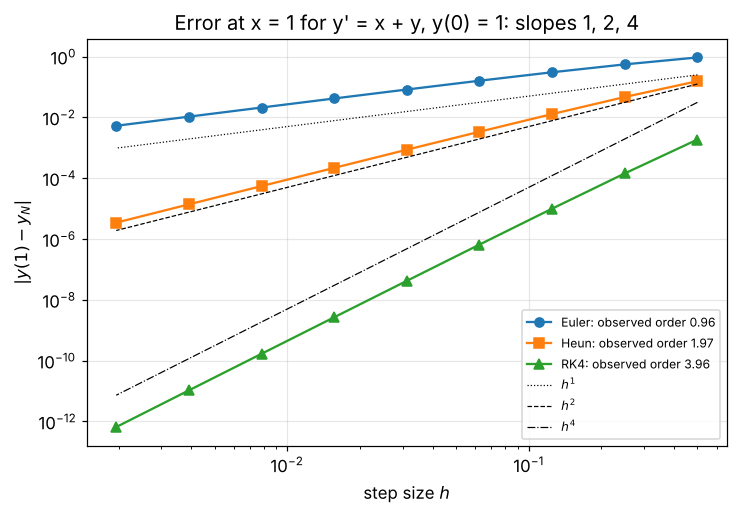

In [4]:
steps = 0.5 / 2.0 ** np.arange(9)
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for name, method, marker in (("Euler", ol.euler, "o"), ("Heun", ol.heun, "s"), ("RK4", ol.rk4, "^")):
    errors = np.array([abs(method(g, (0, 1), 1.0, h)[1][-1] - exact) for h in steps])
    errors = np.maximum(errors, 1e-16)                   # RK4 reaches round-off level
    order = ol.observed_order(errors[:5])[-1]
    ax.loglog(steps, errors, marker + "-", label=f"{name}: observed order {order:.2f}")
for p, style in ((1, ":"), (2, "--"), (4, "-.")):
    ax.loglog(steps, 0.5 * steps**p, "k" + style, lw=0.8, label=rf"$h^{p}$")
ax.set_xlabel("step size $h$")
ax.set_ylabel(r"$|y(1) - y_N|$")
ax.set_title("Error at x = 1 for y' = x + y, y(0) = 1: slopes 1, 2, 4")
ax.legend(fontsize=8)
plt.show()

The RK4 curve flattens at about $10^{-14}$. That is **round-off error**: the computer works with
about 16 significant digits, so very small steps add rounding errors instead of removing
truncation errors (Lebl, end of Section 1.7).

## 4. When the exact solution does not exist: Lebl's Table 1.7.2

For the same equation $y' = y^2/3$, $y(0) = 1$, try to approximate $y(3)$. The exact solution
$y = 3/(3 - x)$ **blows up at $x = 3$**, so there is no value to approximate. Euler's method still
returns numbers, and they never settle as $h$ shrinks. *Stabilising numbers are evidence of
convergence; numbers that keep changing are a warning.*

In [5]:
lebl_table_172 = [3.16232, 4.54329, 6.86079, 10.80321, 17.59893, 29.46004, 50.40121, 87.75769]
for h, book in zip([1 / 2**i for i in range(8)], lebl_table_172, strict=True):
    y3 = ol.euler(f, (0.0, 3.0), 1.0, h)[1][-1]
    print(f"h = {h:9.7f}:  Euler 'y(3)' = {y3:10.5f}   (Lebl: {book:9.5f})")
    assert abs(y3 - book) < 1e-4

h = 1.0000000:  Euler 'y(3)' =    3.16232   (Lebl:   3.16232)
h = 0.5000000:  Euler 'y(3)' =    4.54329   (Lebl:   4.54329)
h = 0.2500000:  Euler 'y(3)' =    6.86079   (Lebl:   6.86079)
h = 0.1250000:  Euler 'y(3)' =   10.80321   (Lebl:  10.80321)
h = 0.0625000:  Euler 'y(3)' =   17.59893   (Lebl:  17.59893)
h = 0.0312500:  Euler 'y(3)' =   29.46004   (Lebl:  29.46004)
h = 0.0156250:  Euler 'y(3)' =   50.40121   (Lebl:  50.40121)
h = 0.0078125:  Euler 'y(3)' =   87.75769   (Lebl:  87.75769)


## 5. Numerical instability (Lebl, Exercise 1.7.4) and absolute stability

Take $y' = -5y$, $y(0) = 1$: the solution $e^{-5x}$ decays to zero. Euler gives
$y_{i+1} = (1 - 5h)\,y_i$, so $y_n = (1 - 5h)^n$:

* $h < 0.2$: $0 < 1 - 5h < 1$, monotone decay, as in reality;
* $0.2 < h < 0.4$: $-1 < 1 - 5h < 0$, decay with **spurious oscillations**;
* $h > 0.4$: $|1 - 5h| > 1$, the numbers **grow** and oscillate. This is pure numerical nonsense.

In general, for the test equation $y' = \lambda y$ with $\mathrm{Re}\,\lambda < 0$, Euler's method
decays if and only if $|1 + h\lambda| < 1$. The set of $z = h\lambda$ with $|1 + z| < 1$ is the
**region of absolute stability** of Euler's method, a disk of radius 1 centred at $-1$
(Meseguer, Section 8.2, eqs. 8.161-8.162). For Heun the condition is
$|1 + z + z^2/2| < 1$ (eq. 8.165). Problems that force very small steps for stability, not for
accuracy, are called **stiff**.

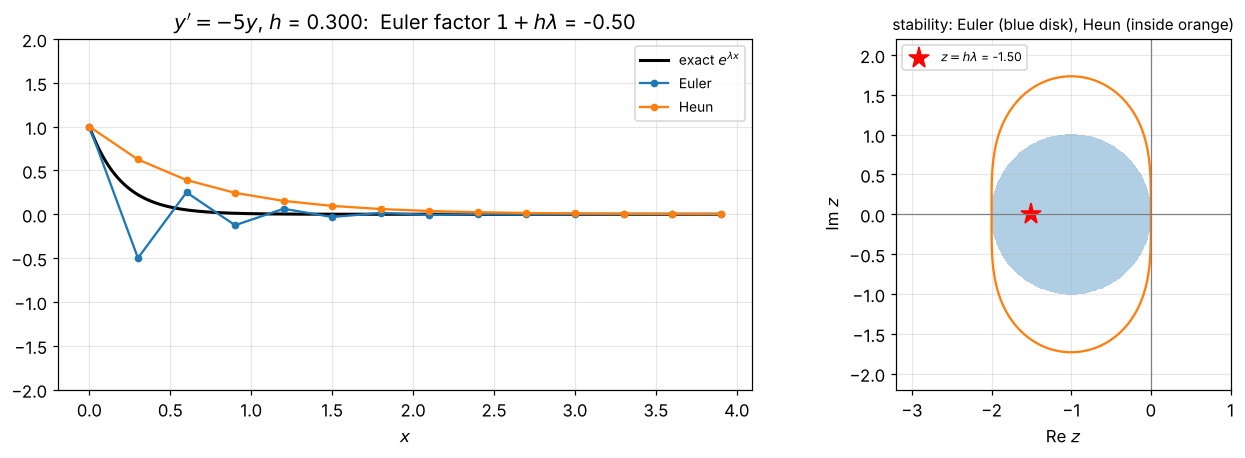

In [6]:
def plot_stability(h=0.3, lam=-5.0, x_end=4.0):
    """Euler and Heun on y' = lam*y versus the exact solution, plus the stability regions."""
    n = max(1, int(round(x_end / h)))
    x_end = n * h
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [3, 2]})
    xx = np.linspace(0, x_end, 400)
    ax1.plot(xx, np.exp(lam * xx), "k", lw=2, label="exact $e^{\\lambda x}$")
    for name, method in (("Euler", ol.euler), ("Heun", ol.heun)):
        try:
            t, y = method(lambda x, y: lam * y, (0, x_end), 1.0, h)
            ax1.plot(t, y, "o-", ms=4, label=name)
        except FloatingPointError:
            ax1.plot([], [], label=f"{name}: overflow")
    ax1.set_ylim(-2, 2)
    ax1.set_xlabel("$x$")
    ax1.legend()
    ax1.set_title(rf"$y' = {lam:g}y$, $h$ = {h:.3f}:  Euler factor $1 + h\lambda$ = {1 + h * lam:.2f}")
    # stability regions in the complex plane z = h*lambda
    re, im = np.meshgrid(np.linspace(-3.2, 1, 400), np.linspace(-2.2, 2.2, 400))
    z = re + 1j * im
    ax2.contourf(re, im, (np.abs(1 + z) < 1).astype(float), levels=[0.5, 1.5], colors=["C0"], alpha=0.35)
    ax2.contour(re, im, np.abs(1 + z + z**2 / 2), levels=[1], colors="C1")
    ax2.plot([h * lam], [0], "r*", ms=14, label=rf"$z = h\lambda$ = {h * lam:.2f}")
    ax2.axhline(0, color="0.5", lw=0.8)
    ax2.axvline(0, color="0.5", lw=0.8)
    ax2.set_aspect("equal")
    ax2.set_xlabel(r"Re $z$")
    ax2.set_ylabel(r"Im $z$")
    ax2.set_title("stability: Euler (blue disk), Heun (inside orange)", fontsize=10)
    ax2.legend(loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.show()


plot_stability(h=0.3)

In [7]:
interact(plot_stability,
         h=FloatSlider(value=0.3, min=0.02, max=0.6, step=0.01, description="h", continuous_update=False),
         lam=FloatSlider(value=-5, min=-20, max=-0.5, step=0.5, description="λ", continuous_update=False),
         x_end=FloatSlider(value=4, min=1, max=10, step=0.5, description="x max", continuous_update=False));

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='h', max=0.6, min=0.02, step…

## 6. Euler's method on the models of notebooks 01-03

The slider sets the step $h$. For each model the exact solution is known, so the true error
is printed.

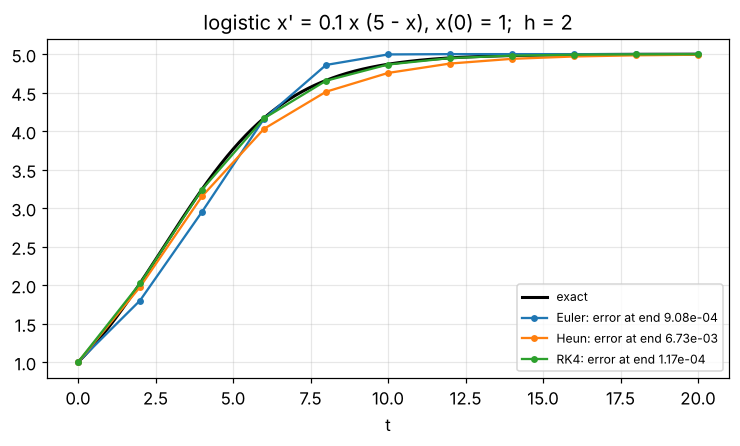

In [8]:
MODELS = {
    "growth  P' = 0.0693 P, P(0) = 100": (lambda t, y: np.log(2) / 10 * y, 100.0, 60.0,
                                           lambda t: ol.exponential_solution(t, 100, np.log(2) / 10)),
    "decay   N' = -0.5 N,  N(0) = 1":    (lambda t, y: -0.5 * y, 1.0, 10.0,
                                           lambda t: ol.exponential_solution(t, 1.0, -0.5)),
    "logistic x' = 0.1 x (5 - x), x(0) = 1": (lambda t, y: 0.1 * y * (5 - y), 1.0, 20.0,
                                              lambda t: ol.logistic_solution(t, 1.0, 0.1, 5.0)),
}


def compare(model="logistic x' = 0.1 x (5 - x), x(0) = 1", n_steps=10):
    f_m, y0, t_end, exact_m = MODELS[model]
    h = t_end / n_steps
    t = np.linspace(0, t_end, 400)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(t, exact_m(t), "k", lw=2, label="exact")
    for name, method in (("Euler", ol.euler), ("Heun", ol.heun), ("RK4", ol.rk4)):
        tt, yy = method(f_m, (0, t_end), y0, h)
        ax.plot(tt, yy, "o-", ms=3.5, label=f"{name}: error at end {abs(yy[-1] - exact_m(t_end)):.2e}")
    ax.set_title(f"{model};  h = {h:.3g}")
    ax.set_xlabel("t")
    ax.legend(fontsize=8)
    plt.show()


compare()

In [9]:
interact(compare, model=list(MODELS),
         n_steps=IntSlider(value=10, min=2, max=200, description="steps", continuous_update=False));

interactive(children=(Dropdown(description='model', index=2, options=("growth  P' = 0.0693 P, P(0) = 100", "de…

## 7. In practice: `scipy.integrate.solve_ivp`

Professional solvers vary the step automatically to keep an *estimate* of the local error below a
tolerance (`rtol`, `atol`). The default `RK45` uses an embedded pair of Runge-Kutta formulas,
and for stiff problems implicit methods (`Radau`, `BDF`, `LSODA`) are available.

In [10]:
for rtol in (1e-3, 1e-6, 1e-9):
    sol = solve_ivp(lambda t, y: 0.1 * y * (5 - y), (0, 20), [1.0], rtol=rtol, atol=1e-12)
    err = abs(sol.y[0, -1] - ol.logistic_solution(20.0, 1.0, 0.1, 5.0))
    print(f"rtol = {rtol:.0e}: {sol.t.size:4d} points, {sol.nfev:5d} evaluations of f, error {err:.2e}")

# A stiff problem: y' = -1000 (y - cos t). Explicit RK45 needs tiny steps, implicit Radau does not.
stiff = lambda t, y: -1000 * (y - np.cos(t))                 # noqa: E731
for method in ("RK45", "Radau"):
    sol = solve_ivp(stiff, (0, 10), [0.0], method=method, rtol=1e-6)
    print(f"stiff problem with {method:5s}: {sol.t.size:5d} steps")

rtol = 1e-03:    9 points,    56 evaluations of f, error 1.63e-04
rtol = 1e-06:   22 points,   140 evaluations of f, error 4.88e-07
rtol = 1e-09:   71 points,   440 evaluations of f, error 8.30e-10
stiff problem with RK45 :  3277 steps
stiff problem with Radau:    69 steps


## 8. Exercises

1. *(Lebl, Exercise 1.7.2)* Assume you do not know the exact $y(2)$. From the last two lines of
   Table 1.7.1, estimate the error of the last approximation, assuming the error halves at
   each halving of $h$ (*Richardson extrapolation*). Compare with the true error.
2. Prove that Heun's method is exact for $y' = 2x$ (any $h$). Is it exact for $y' = 3x^2$? Explain
   with the local truncation error.
3. *(Lebl, Exercise 1.7.4)* For $y' = -5y$, find the largest $h$ for which Euler's iterates do not
   oscillate, and the largest $h$ for which they decay. Check with the slider.
4. Show that Heun's method applied to $y' = \lambda y$ gives $y_{n+1} = (1 + z + z^2/2)\,y_n$ with
   $z = h\lambda$. For real $\lambda < 0$, find the stability interval ($-2 < z < 0$).
5. Apply Euler's method to the logistic equation of notebook 03 with $h = 25$ (so $hkM = 12.5$).
   What do the iterates do? Relate the answer to Section 4 of notebook 03.